In [1]:
import json
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

In [2]:
folders = ["DSN", "GCG", "JBC", "PAIR", "prompt_with_random_search"]
models = {
    "llama": "llama-2-7b-chat-hf.json",
    "vicuna": "vicuna-13b-v1.5.json",
    "gpt3.5": "gpt-3.5-turbo-1106.json",
    "gpt4": "gpt-4-0125-preview.json"
}

cols = ["number_of_queries", "queries_to_jailbreak",
            "prompt_tokens", "response_tokens"]

frames = []
for folder in folders:
    for model, filename in models.items():
        path = Path("../data/raw_jailbenchmark/attack-artifacts") / folder / filename
        if path.exists():
            with open(path, encoding="utf-8") as f:
                data = json.load(f)

            df = pd.DataFrame(data["jailbreaks"])
            df[cols] = df[cols].astype("float64")   # all-null columns become NaN floats
            df["generating_method"] = folder
            df["model"] = model
            frames.append(df)

attack_df = pd.concat(frames, ignore_index=True)

In [3]:
# Remove rows without prompt or response
attack_df = attack_df[~attack_df.prompt.isna()]
attack_df = attack_df[~attack_df.response.isna()]

# Reset index
attack_df = attack_df.drop(columns=['index'])
attack_df = attack_df.reset_index(drop=True)

In [4]:
import re, string
import numpy as np

# Prompt related features
p = attack_df["prompt"]
g = attack_df["goal"]

# Mean characters per word
attack_df["prompt_words"] = p.str.split().str.len()
attack_df["avg_word_len"] = p.str.replace(r"\s+", "", regex=True).str.len() / attack_df["prompt_words"].clip(lower=1)

def type_token_ratio(text):
    words = re.findall(r"[a-z']+", text.lower())
    return len(set(words)) / len(words) if words else 0.0

# All of the following are removed for having high correlation with existing features
# Prompt length divided by goal length (~how verbose the prompt is)
# attack_df["prompt_chars"] = p.str.len()
# attack_df["len_ratio"] = attack_df["prompt_chars"] / g.str.len()
# Distinct words divided by total words (vocabulary variety)
# attack_df["type_token_ratio"] = p.apply(type_token_ratio)
# Number of directives
# attack_df["n_directives"] = p.str.count(
#     r"(?i)\b(?:must|always|never|ensure|make sure|do not|don't|should|exactly|precisely|remember)\b")

In [5]:
# More prompt related features

# % of characters outside plain English
def char_share(text, test):
    chars = [c for c in text if not c.isspace()]
    return sum(test(c) for c in chars) / len(chars) if chars else 0.0
attack_df["non_ascii_share"] = p.apply(char_share, test=lambda c: ord(c) > 127)

# How unpredictable the mix of characters is
def char_entropy(text):
    if not text:
        return 0.0
    # *counts* is a vector (distribution) containing the number of times each word shows up
    _, counts = np.unique(list(text), return_counts=True)
    prob = counts / counts.sum()
    return float(-(prob * np.log2(prob)).sum())
attack_df["char_entropy"] = p.apply(char_entropy)

In [6]:
# Embedding - shrunk to 10 columns to not overwhelm the other features
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(sublinear_tf=True, min_df=2, ngram_range=(1, 2))
prompt_emb = TruncatedSVD(n_components=50, random_state=0).fit_transform(tfidf.fit_transform(p))

from sklearn.decomposition import PCA
emb_cols = [f"emb_{i}" for i in range(10)]
attack_df[emb_cols] = PCA(n_components=10, random_state=0).fit_transform(prompt_emb)

In [7]:
# Prompt sentiment (better options might be available)
# from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
# vader = SentimentIntensityAnalyzer()

# def sentiment(text):
#     parts = [s for s in re.split(r"(?<=[.!?])\s+|\n+", text) if s.strip()]
#     return float(np.mean([vader.polarity_scores(s)["compound"] for s in parts])) if parts else 0.0

# attack_df["prompt_sentiment"] = p.apply(sentiment)

In [8]:
# Might remove len_ratio

# Remove columns with too many nans
attack_df = attack_df.drop(columns=['number_of_queries', 'queries_to_jailbreak', 'prompt_tokens', 'response_tokens', 'jailbroken_llama_guard1'])

In [9]:
# Add model benchmark scores

# arena scores source: https://github.com/lmarena/arena-catalog/blob/main/data/leaderboard-text.json
# arena_creative_writing = {"llama": 1035.9, "vicuna": 1059.3, "gpt3.5": 1036.2, "gpt4": 1233.7}
arena_expert = {"llama": 1032, "vicuna": 992, "gpt3.5": 1067, "gpt4": 1203}

# EQ_bench source: https://huggingface.co/spaces/sam-paech/EQ-Bench-Leaderboard/raw/main/script.js
EQ_bench = {"llama": 36, "vicuna": 67, "gpt3.5": 72, "gpt4": 84}

# Sorry_bench https://arxiv.org/html/2406.14598v2, table 4
# This might be a forward-looking bias
sorry_bench = {"llama": 14, "vicuna": 32, "gpt3.5": 11, "gpt4": 26}
# sorry_bench = {"llama": 13.86, "vicuna": 32.27, "gpt3.5": 10.68, "gpt4": 26.36}

# Number of parameters (in billions). GPT models have estimated number of parameters
# num_params = {"llama": 7, "vicuna": 13, "gpt3.5": 20, "gpt4": 1800}

attack_df['arena_expert'] = attack_df['model'].map(arena_expert)
attack_df['EQ_bench'] = attack_df['model'].map(EQ_bench)
attack_df['sorry_bench'] = attack_df['model'].map(sorry_bench)

In [10]:
# Get the five generating methods
attack_df = pd.get_dummies(attack_df, columns=["generating_method"], prefix="method", dtype=int)
method_cols = [c for c in attack_df.columns if c.startswith("method_")]

In [11]:
numeric_cols = ['prompt_words', 'avg_word_len', 'non_ascii_share', 'char_entropy',
                'emb_0', 'emb_1', 'emb_2', 'emb_3', 'emb_4',
                'emb_5', 'emb_6', 'emb_7', 'emb_8', 'emb_9']
bench_cols = ['arena_expert', 'EQ_bench', 'sorry_bench']
interaction_cols = [f"{b}_x_{n}" for b in bench_cols for n in numeric_cols]
interaction_cols = interaction_cols + [f"{b}_x_{m}" for b in bench_cols for m in method_cols]

In [12]:
# Add interaction columns
new_columns = {}
for b in bench_cols:
    for n in numeric_cols:
        new_columns[f"{b}_x_{n}"] = attack_df[b] * attack_df[n]
for b in bench_cols:
    for m in method_cols:
        new_columns[f"{b}_x_{m}"] = attack_df[b] * attack_df[m]
attack_df = attack_df.assign(**new_columns)

In [13]:
attack_df.to_csv("../data/processed_data_v2.csv", index=False)

In [14]:
linear_features = numeric_cols + bench_cols + interaction_cols + method_cols[1:] # drops the first column to avoid collinearity
tree_features = numeric_cols + bench_cols + method_cols
scale_cols = numeric_cols + bench_cols + interaction_cols

In [15]:
def fold_metrics(y_true, y_score, threshold):
    """Metrics for one fold. AUC uses the raw scores; the others use 0/1 predictions at the threshold."""
    y_pred = (y_score >= threshold).astype(int)
    return {"accuracy":  accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall":    recall_score(y_true, y_pred),
            "f1":        f1_score(y_true, y_pred, zero_division=0),
            "auc":       roc_auc_score(y_true, y_score)}

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold

# Mixing all the models together so the task of only predicting on gpt-4 is easier
# Set up 5-fold CV
train_val_data, data_test = train_test_split(attack_df, test_size=0.2, random_state=120)
y_cv = train_val_data["jailbroken"].astype(int) # Contains all train/val labels
kf = KFold(n_splits=5, shuffle=True, random_state=120)

In [17]:
train_val_data['jailbroken'].value_counts()

jailbroken
True     748
False    561
Name: count, dtype: int64

In [18]:
data_test['jailbroken'].value_counts()

jailbroken
True     189
False    139
Name: count, dtype: int64

In [19]:
train_val_data.groupby('model')['jailbroken'].value_counts()

model   jailbroken
gpt3.5  True          165
        False         136
gpt4    False         208
        True           93
llama   False         173
        True          150
vicuna  True          340
        False          44
Name: count, dtype: int64

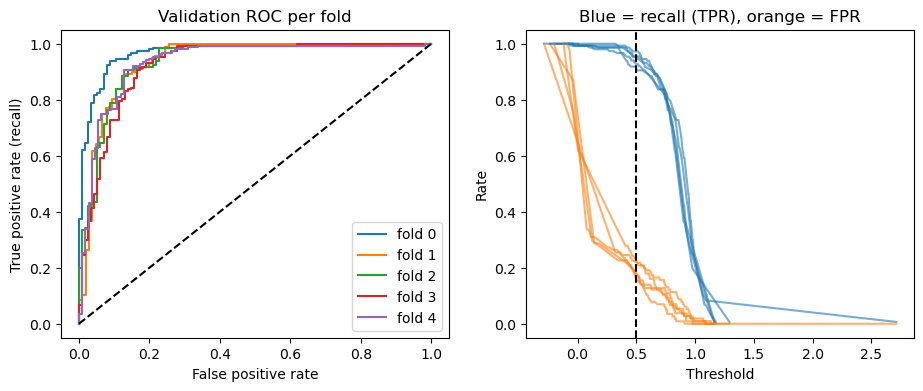

           train    val
accuracy   0.905  0.887
precision  0.885  0.870
recall     0.958  0.944
f1         0.920  0.905
auc        0.959  0.941


In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, precision_score,
                             recall_score, accuracy_score, f1_score, roc_auc_score, roc_curve)

# One dictionary of metrics per fold
train_rows, val_rows = [], []

# For graphing AUC ROC per fold
fig, (ax_roc, ax_thr) = plt.subplots(1, 2, figsize=(11, 4))

for fold, (train_idx, val_idx) in enumerate(kf.split(train_val_data)):
    # Get train/val data
    train_data = train_val_data.iloc[train_idx].copy()
    val_data = train_val_data.iloc[val_idx].copy()
    scaler = StandardScaler()
    train_data[scale_cols] = scaler.fit_transform(train_val_data[scale_cols].iloc[train_idx])
    val_data[scale_cols] = scaler.transform(train_val_data[scale_cols].iloc[val_idx])
    y_train, y_val = y_cv.iloc[train_idx], y_cv.iloc[val_idx]
    # clip the data to remove the effect of outliers
    train_data[scale_cols] = np.clip(train_data[scale_cols], -2, 2)
    val_data[scale_cols] = np.clip(val_data[scale_cols], -2, 2)

    # Apply OLS
    OLS = LinearRegression()
    OLS.fit(train_data[linear_features], y_train)
    y_train_score = OLS.predict(train_data[linear_features])
    y_val_score = OLS.predict(val_data[linear_features])
    # Choosing threshold as 0.5 to "maximize" recall (don't want false negatives for jailbreak attempts)
    threshold = 0.5
    train_rows.append(fold_metrics(y_train, y_train_score, threshold))
    val_rows.append(fold_metrics(y_val, y_val_score, threshold))

    # Graph the ROC curve
    fpr, tpr, thr = roc_curve(y_val, y_val_score)
    ax_roc.plot(fpr, tpr, label=f"fold {fold}")
    ax_thr.plot(thr[1:], tpr[1:], color="C0", alpha=0.6)
    ax_thr.plot(thr[1:], fpr[1:], color="C1", alpha=0.6)

ax_roc.plot([0, 1], [0, 1], "k--")   # what random guessing looks like
ax_roc.set(xlabel="False positive rate", ylabel="True positive rate (recall)", title="Validation ROC per fold")
ax_roc.legend()
ax_thr.axvline(threshold, color="k", ls="--")   # your current threshold
ax_thr.set(xlabel="Threshold", ylabel="Rate", title="Blue = recall (TPR), orange = FPR")
plt.show()

summary = pd.DataFrame({"train": pd.DataFrame(train_rows).mean(),
                        "val":   pd.DataFrame(val_rows).mean()})
print(summary.round(3))
  

In [21]:
val_data.describe()

,prompt_words,avg_word_len,non_ascii_share,char_entropy,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5,...,EQ_bench_x_method_DSN,EQ_bench_x_method_GCG,EQ_bench_x_method_JBC,EQ_bench_x_method_PAIR,EQ_bench_x_method_prompt_with_random_search,sorry_bench_x_method_DSN,sorry_bench_x_method_GCG,sorry_bench_x_method_JBC,sorry_bench_x_method_PAIR,sorry_bench_x_method_prompt_with_random_search
count,261.000000,261.000000,261.000000,261.000000,261.000000,261.000000,261.000000,261.000000,261.000000,261.000000,...,261.000000,261.000000,261.000000,261.000000,261.000000,261.000000,261.000000,261.000000,261.000000,261.000000
mean,0.025522,-0.061706,-0.119426,-0.050520,-0.008006,0.023902,-0.137499,-0.056089,0.108855,0.034188,...,-0.122103,0.001637,-0.001092,-0.068265,0.010832,-0.131008,-0.040014,-0.037288,-0.108964,-0.037010
std,1.002971,0.850815,0.573060,1.007567,1.015587,1.001203,0.634758,0.701050,0.839608,0.890428,...,0.681714,0.980044,0.971089,0.833405,0.986613,0.632905,0.886418,0.890725,0.687246,0.884586
min,-1.192692,-1.807550,-0.472311,-2.000000,-1.709618,-1.218688,-2.000000,-1.253395,-2.000000,-2.000000,...,-0.361669,-0.538358,-0.550390,-0.405406,-0.532870,-0.350809,-0.511238,-0.522536,-0.375074,-0.507056
25%,-1.070660,-0.819064,-0.472311,-0.510976,-1.505729,-0.912968,-0.326596,-0.453858,-0.020181,-0.581459,...,-0.361669,-0.538358,-0.550390,-0.405406,-0.532870,-0.350809,-0.511238,-0.522536,-0.375074,-0.507056
50%,0.904729,-0.205264,-0.472311,-0.371818,0.271534,0.513471,-0.041177,-0.007310,0.026688,-0.145348,...,-0.361669,-0.538358,-0.550390,-0.405406,-0.532870,-0.350809,-0.511238,-0.522536,-0.375074,-0.507056
75%,0.988626,0.427534,-0.006199,0.839761,0.322481,0.682245,0.020124,0.101076,0.099539,0.538234,...,-0.361669,-0.538358,0.666719,-0.405406,-0.532870,-0.350809,-0.511238,0.579714,-0.375074,-0.507056
max,1.270825,2.000000,2.000000,1.602917,1.215624,1.613191,2.000000,2.000000,2.000000,2.000000,...,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000


# Grid search on other ML models

In [22]:
def run_cv(model, features, threshold):
    """5-fold CV for one model with one hyperparameter setting."""
    train_rows, val_rows = [], []
    for train_idx, val_idx in kf.split(train_val_data):
        # Same steps as the OLS loop
        train_data = train_val_data.iloc[train_idx].copy()
        val_data = train_val_data.iloc[val_idx].copy()
        scaler = StandardScaler()
        train_data[scale_cols] = scaler.fit_transform(train_val_data[scale_cols].iloc[train_idx])
        val_data[scale_cols] = scaler.transform(train_val_data[scale_cols].iloc[val_idx])
        train_data[scale_cols] = np.clip(train_data[scale_cols], -2, 2)
        val_data[scale_cols] = np.clip(val_data[scale_cols], -2, 2)
        y_train, y_val = y_cv.iloc[train_idx], y_cv.iloc[val_idx]

        model.fit(train_data[features], y_train)
        # predict_proba gives [P(not jailbroken), P(jailbroken)]; keep the second column
        y_train_score = model.predict_proba(train_data[features])[:, 1]
        y_val_score = model.predict_proba(val_data[features])[:, 1]
        train_rows.append(fold_metrics(y_train, y_train_score, threshold))
        val_rows.append(fold_metrics(y_val, y_val_score, threshold))
    return train_rows, val_rows


def summarize(params, train_rows, val_rows):
    """One table row: the hyperparameters + 5-fold averages of each train and val metric."""
    row = dict(params)
    row.update(pd.DataFrame(train_rows).mean().add_prefix("train_").to_dict())
    row.update(pd.DataFrame(val_rows).mean().add_prefix("val_").to_dict())
    return row

In [23]:
threshold = 0.5

In [24]:
from sklearn.linear_model import LogisticRegression

grid_rows = []   # one row per hyperparameter setting
for C in [0.01, 0.05, 0.1, 0.5, 1, 5, 10]:   # smaller C = stronger penalty
    train_rows, val_rows = run_cv(LogisticRegression(C=C, max_iter=1000), linear_features, threshold)
    grid_rows.append(summarize({"C": C}, train_rows, val_rows))

logistic_table = pd.DataFrame(grid_rows).sort_values("val_auc", ascending=False)
logistic_table.round(3)

,C,train_accuracy,train_precision,train_recall,train_f1,train_auc,val_accuracy,val_precision,val_recall,val_f1,val_auc
5,5.00,0.901,0.884,0.951,0.916,0.960,0.885,0.872,0.936,0.903,0.944
6,10.00,0.903,0.887,0.953,0.918,0.961,0.885,0.871,0.937,0.903,0.944
4,1.00,0.892,0.878,0.941,0.908,0.954,0.883,0.871,0.935,0.901,0.942
3,0.50,0.888,0.878,0.935,0.906,0.950,0.877,0.867,0.926,0.896,0.940
2,0.10,0.880,0.879,0.917,0.898,0.942,0.870,0.869,0.910,0.889,0.934
1,0.05,0.879,0.881,0.911,0.896,0.938,0.870,0.873,0.905,0.888,0.931
0,0.01,0.872,0.865,0.920,0.892,0.926,0.869,0.864,0.915,0.888,0.920


In [25]:
# Decision tree
from sklearn.tree import DecisionTreeClassifier
grid_rows = []
for depth in [2, 3, 4, 5, 6, None]:
    for leaf in [1, 5, 10, 20, 30]:
        model = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=120)
        train_rows, val_rows = run_cv(model, tree_features, threshold)
        grid_rows.append(summarize({"max_depth": str(depth), "min_samples_leaf": leaf}, train_rows, val_rows))
tree_table = pd.DataFrame(grid_rows).sort_values("val_auc", ascending=False)
tree_table.round(3)

,max_depth,min_samples_leaf,train_accuracy,train_precision,train_recall,train_f1,train_auc,val_accuracy,val_precision,val_recall,val_f1,val_auc
18,5,20,0.883,0.867,0.939,0.901,0.956,0.857,0.845,0.920,0.880,0.934
13,4,20,0.874,0.872,0.917,0.893,0.943,0.853,0.851,0.903,0.875,0.934
23,6,20,0.888,0.877,0.935,0.905,0.961,0.859,0.848,0.917,0.881,0.930
17,5,10,0.892,0.887,0.930,0.908,0.960,0.853,0.852,0.901,0.875,0.930
12,4,10,0.881,0.874,0.927,0.899,0.945,0.858,0.851,0.912,0.880,0.929
11,4,5,0.887,0.875,0.937,0.904,0.945,0.863,0.854,0.919,0.884,0.929
28,None,20,0.888,0.880,0.932,0.905,0.963,0.856,0.850,0.911,0.879,0.928
19,5,30,0.874,0.860,0.933,0.894,0.950,0.854,0.844,0.915,0.878,0.928
10,4,1,0.889,0.879,0.937,0.906,0.946,0.862,0.854,0.917,0.884,0.928
16,5,5,0.896,0.883,0.945,0.912,0.961,0.857,0.852,0.907,0.879,0.928


In [26]:
# Random forest
from sklearn.ensemble import RandomForestClassifier
grid_rows = []
for mf in [0.1, 0.3, 0.5]:
    for depth in [2, 3, 4, None]:
        for leaf in [1, 5, 10]:
            model = RandomForestClassifier(n_estimators=300, max_depth=depth, max_features=mf, min_samples_leaf=leaf,
                                        random_state=120, n_jobs=-1)
            train_rows, val_rows = run_cv(model, tree_features, threshold)
            grid_rows.append(summarize({"max_features": mf, "min_samples_leaf": leaf, "max_depth": depth}, train_rows, val_rows))
rf_table = pd.DataFrame(grid_rows).sort_values("val_auc", ascending=False)
rf_table.round(3)

,max_features,min_samples_leaf,max_depth,train_accuracy,train_precision,train_recall,train_f1,train_auc,val_accuracy,val_precision,val_recall,val_f1,val_auc
9,0.1,1,NaN,1.000,1.000,1.000,1.000,1.000,0.884,0.867,0.941,0.903,0.946
21,0.3,1,NaN,1.000,1.000,1.000,1.000,1.000,0.882,0.864,0.941,0.901,0.945
34,0.5,5,NaN,0.954,0.937,0.986,0.961,0.993,0.867,0.848,0.936,0.889,0.945
22,0.3,5,NaN,0.947,0.927,0.986,0.955,0.992,0.876,0.861,0.935,0.896,0.944
10,0.1,5,NaN,0.924,0.903,0.971,0.936,0.987,0.877,0.859,0.940,0.897,0.944
31,0.5,5,4.0,0.882,0.869,0.934,0.900,0.963,0.870,0.856,0.929,0.891,0.944
30,0.5,1,4.0,0.887,0.877,0.934,0.905,0.965,0.875,0.862,0.931,0.895,0.944
33,0.5,1,NaN,1.000,1.000,1.000,1.000,1.000,0.887,0.869,0.946,0.905,0.943
23,0.3,10,NaN,0.908,0.882,0.968,0.923,0.979,0.872,0.856,0.935,0.893,0.943
35,0.5,10,NaN,0.917,0.893,0.971,0.930,0.981,0.865,0.845,0.935,0.888,0.943


In [27]:
# Gradient boosting
from sklearn.ensemble import GradientBoostingClassifier
grid_rows = []
for lr in [0.05, 0.1]:
    for depth in [2, 3, 4]:
        for n in [100, 300]:
            model = GradientBoostingClassifier(learning_rate=lr, max_depth=depth, n_estimators=n, random_state=120)
            train_rows, val_rows = run_cv(model, tree_features, threshold)
            grid_rows.append(summarize({"learning_rate": lr, "max_depth": depth, "n_estimators": n},
                                       train_rows, val_rows))
gb_table = pd.DataFrame(grid_rows).sort_values("val_auc", ascending=False)
gb_table.round(3)

,learning_rate,max_depth,n_estimators,train_accuracy,train_precision,train_recall,train_f1,train_auc,val_accuracy,val_precision,val_recall,val_f1,val_auc
4,0.05,4,100,0.957,0.946,0.982,0.963,0.993,0.882,0.871,0.931,0.900,0.949
2,0.05,3,100,0.924,0.915,0.956,0.935,0.980,0.872,0.868,0.914,0.891,0.949
3,0.05,3,300,0.980,0.973,0.994,0.983,0.998,0.878,0.876,0.917,0.896,0.949
10,0.10,4,100,0.990,0.985,0.997,0.991,1.000,0.883,0.871,0.933,0.901,0.948
1,0.05,2,300,0.933,0.925,0.960,0.942,0.984,0.877,0.877,0.913,0.895,0.948
7,0.10,2,300,0.970,0.961,0.987,0.974,0.995,0.875,0.876,0.911,0.893,0.947
11,0.10,4,300,1.000,1.000,1.000,1.000,1.000,0.885,0.874,0.933,0.902,0.947
8,0.10,3,100,0.959,0.949,0.981,0.965,0.993,0.876,0.871,0.920,0.895,0.946
5,0.05,4,300,0.999,0.998,1.000,0.999,1.000,0.885,0.874,0.933,0.902,0.946
9,0.10,3,300,0.999,0.999,1.000,0.999,1.000,0.879,0.875,0.920,0.896,0.946


In [28]:
# XGBoost
from xgboost import XGBClassifier
grid_rows = []
for lr in [0.05, 0.1]:
    for depth in [2, 3, 4]:
        for n in [100, 300]:
            model = XGBClassifier(learning_rate=lr, max_depth=depth, n_estimators=n, random_state=120)
            train_rows, val_rows = run_cv(model, tree_features, threshold)
            grid_rows.append(summarize({"learning_rate": lr, "max_depth": depth, "n_estimators": n},
                                       train_rows, val_rows))
xgb_table = pd.DataFrame(grid_rows).sort_values("val_auc", ascending=False)
xgb_table.round(3)

,learning_rate,max_depth,n_estimators,train_accuracy,train_precision,train_recall,train_f1,train_auc,val_accuracy,val_precision,val_recall,val_f1,val_auc
3,0.05,3,300,0.963,0.949,0.989,0.968,0.995,0.882,0.879,0.921,0.900,0.952
4,0.05,4,100,0.939,0.925,0.971,0.947,0.985,0.879,0.871,0.925,0.897,0.952
5,0.05,4,300,0.989,0.983,0.999,0.991,1.000,0.883,0.877,0.925,0.901,0.951
10,0.10,4,100,0.974,0.963,0.994,0.978,0.998,0.882,0.881,0.919,0.899,0.951
8,0.10,3,100,0.945,0.932,0.975,0.953,0.988,0.883,0.880,0.921,0.900,0.951
11,0.10,4,300,1.000,1.000,1.000,1.000,1.000,0.884,0.880,0.924,0.901,0.950
2,0.05,3,100,0.912,0.903,0.948,0.925,0.973,0.872,0.869,0.913,0.890,0.950
7,0.10,2,300,0.955,0.942,0.982,0.961,0.992,0.882,0.876,0.925,0.900,0.950
9,0.10,3,300,0.994,0.990,0.999,0.994,1.000,0.881,0.881,0.916,0.898,0.949
1,0.05,2,300,0.923,0.909,0.961,0.934,0.978,0.879,0.872,0.925,0.898,0.948


# Test (This should go in a new notebook)

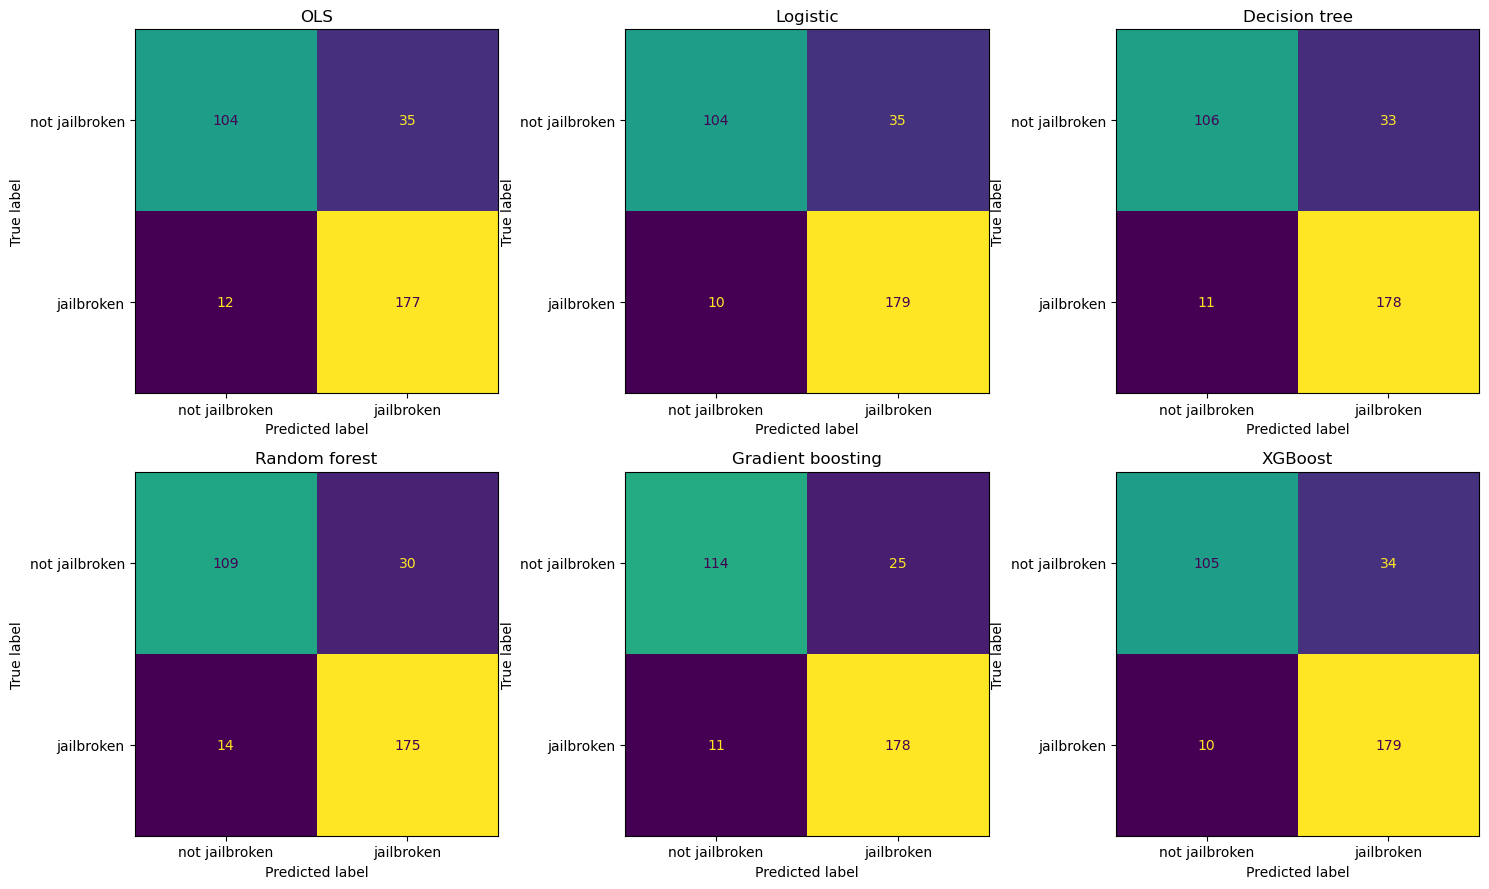

,accuracy,precision,recall,f1,auc
OLS,0.857,0.835,0.937,0.883,0.921
Logistic,0.863,0.836,0.947,0.888,0.923
Decision tree,0.866,0.844,0.942,0.890,0.912
Random forest,0.866,0.854,0.926,0.888,0.929
Gradient boosting,0.890,0.877,0.942,0.908,0.943
XGBoost,0.866,0.840,0.947,0.891,0.942


In [29]:
# Scale once: fit the scaler on all train/val rows, apply it to the test rows
train_full = train_val_data.copy()
test_full = data_test.copy()
scaler = StandardScaler()
train_full[scale_cols] = scaler.fit_transform(train_val_data[scale_cols])
test_full[scale_cols] = scaler.transform(data_test[scale_cols])
train_full[scale_cols] = np.clip(train_full[scale_cols], -2, 2)
test_full[scale_cols] = np.clip(test_full[scale_cols], -2, 2)
y_test = data_test["jailbroken"].astype(int)

# Your chosen model + settings, and which feature list it uses   <- edit these
final_models = {
    "OLS":               (LinearRegression(), linear_features),
    "Logistic":          (LogisticRegression(C=5, max_iter=1000), linear_features),
    "Decision tree":     (DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=120), tree_features),
    "Random forest":     (RandomForestClassifier(n_estimators=300, max_features=0.1, min_samples_leaf=5,
                                                 random_state=120, n_jobs=-1), tree_features),
    "Gradient boosting": (GradientBoostingClassifier(learning_rate=0.05, max_depth=4, n_estimators=100,
                                                     random_state=120), tree_features),
    "XGBoost":           (XGBClassifier(learning_rate=0.05, max_depth=3, n_estimators=300,
                                        random_state=120), tree_features),
}

threshold = 0.5
test_rows = {}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()  # turn the 2x3 grid into a flat list of 6 axes

for i, name in enumerate(final_models):
    model, features = final_models[name]
    model.fit(train_full[features], y_cv)

    # OLS has no predict_proba, so use its raw prediction
    if name == "OLS":
        y_test_score = model.predict(test_full[features])
    else:
        y_test_score = model.predict_proba(test_full[features])[:, 1]

    test_rows[name] = fold_metrics(y_test, y_test_score, threshold)

    y_test_pred = (y_test_score >= threshold).astype(int)
    cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["not jailbroken", "jailbroken"]).plot(ax=axes[i], colorbar=False)
    axes[i].set_title(name)

plt.tight_layout()
plt.show()

test_table = pd.DataFrame(test_rows).T   # .T = one row per model
test_table.round(3)